# Person 1 — Research Questions, Charts & Analysis
**RQ1:** Do ZIP codes with more affordable housing units also have more serious crashes? *(Scatter plot)*
**RQ2:** Which boroughs have the highest affordable housing production and serious crash counts? *(Grouped bar chart)*

Input: `df_integrated` — housing and SIRTA data aggregated by `zip_code + year` and merged (Person 3).

## Setup — load `df_integrated`
If `df_integrated` is not already in memory, this cell asks you to upload `df_integrated.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

if "df_integrated" not in globals():
    if not os.path.exists("df_integrated.csv"):
        from google.colab import files
        files.upload()          # choose df_integrated.csv
    df_integrated = pd.read_csv("df_integrated.csv")

print(df_integrated.shape)
df_integrated.head()

(484, 11)


,zip_code,year,housing_building_count,housing_project_count,affordable_units,total_housing_units,serious_crash_count,severe_injuries,non_severe_injuries,fatalities,borough
0,10002,2022,3.0,3.0,258.0,316.0,4.0,4.0,0.0,0.0,Manhattan
1,10011,2022,1.0,1.0,26.0,26.0,4.0,4.0,0.0,0.0,Manhattan
2,10018,2022,3.0,3.0,176.0,660.0,1.0,1.0,0.0,0.0,Manhattan
3,10023,2022,1.0,1.0,173.0,174.0,5.0,5.0,2.0,0.0,Manhattan
4,10024,2022,1.0,1.0,189.0,189.0,1.0,1.0,0.0,0.0,Manhattan


In [2]:
HOUSING_COL = "affordable_units"
CRASH_COL   = "serious_crash_count"
BOROUGHS    = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]

df = df_integrated.copy()
df["zip_code"] = df["zip_code"].astype(int).astype(str).str.zfill(5)
df[[HOUSING_COL, CRASH_COL]] = df[[HOUSING_COL, CRASH_COL]].fillna(0)
df["borough"] = df["borough"].astype(str).str.strip().str.title()

print("Years:", sorted(df["year"].astype(int).unique().tolist()))
print("ZIP codes:", df["zip_code"].nunique())
df[[HOUSING_COL, CRASH_COL]].describe()

Years: [2022, 2023, 2024, 2025, 2026]
ZIP codes: 143


,affordable_units,serious_crash_count
count,484.000000,484.000000
mean,232.826446,12.150826
std,311.514963,8.889940
min,1.000000,1.000000
25%,28.500000,5.000000
50%,112.000000,10.000000
75%,321.000000,18.000000
max,2350.000000,43.000000


## RQ1 — Do ZIP codes with more affordable housing units also have more serious crashes?
We total affordable units and serious crashes per ZIP code across all years, then plot them with a regression line and test the relationship with:
- **Pearson r**: linear relationship
- **Spearman ρ**: rank-based, robust to a few very large ZIPs (outliers)

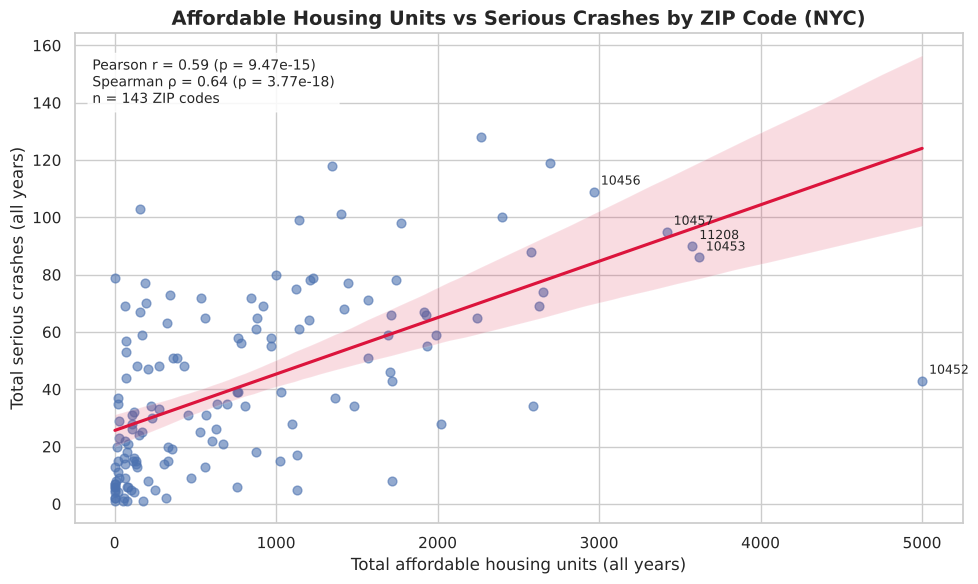

In [3]:
zip_df = (df.groupby("zip_code", as_index=False)
            .agg(affordable_units=(HOUSING_COL, "sum"),
                 serious_crashes=(CRASH_COL, "sum"),
                 borough=("borough", lambda s: s.mode().iat[0])))

pearson_r, pearson_p   = stats.pearsonr(zip_df.affordable_units, zip_df.serious_crashes)
spearman_r, spearman_p = stats.spearmanr(zip_df.affordable_units, zip_df.serious_crashes)

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=zip_df, x="affordable_units", y="serious_crashes",
            scatter_kws={"alpha": 0.6, "s": 40}, line_kws={"color": "crimson"}, ax=ax)

for _, r in zip_df.nlargest(5, "affordable_units").iterrows():
    ax.annotate(r.zip_code, (r.affordable_units, r.serious_crashes),
                textcoords="offset points", xytext=(5, 5), fontsize=9)

ax.set_title("Affordable Housing Units vs Serious Crashes by ZIP Code (NYC)", fontsize=14, weight="bold")
ax.set_xlabel("Total affordable housing units (all years)")
ax.set_ylabel("Total serious crashes (all years)")
ax.text(0.02, 0.95, f"Pearson r = {pearson_r:.2f} (p = {pearson_p:.3g})\n"
                    f"Spearman ρ = {spearman_r:.2f} (p = {spearman_p:.3g})\n"
                    f"n = {len(zip_df)} ZIP codes",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
plt.tight_layout()
plt.savefig("rq1_housing_vs_crashes_scatter.png", dpi=150)
plt.show()

In [4]:
def strength(r):
    a = abs(r)
    return "very weak" if a < 0.2 else "weak" if a < 0.4 else "moderate" if a < 0.7 else "strong"

direction   = "positive" if spearman_r > 0 else "negative"
significant = "statistically significant" if spearman_p < 0.05 else "NOT statistically significant"
print(f"RQ1 finding: {strength(spearman_r)} {direction} relationship "
      f"(Spearman ρ = {spearman_r:.2f}, p = {spearman_p:.3g}) — {significant} at the 5% level.\n")

print("Top 5 ZIPs by affordable units:")
print(zip_df.nlargest(5, "affordable_units").to_string(index=False))
print("\nTop 5 ZIPs by serious crashes:")
print(zip_df.nlargest(5, "serious_crashes").to_string(index=False))

RQ1 finding: moderate positive relationship (Spearman ρ = 0.64, p = 3.77e-18) — statistically significant at the 5% level.

Top 5 ZIPs by affordable units:
zip_code  affordable_units  serious_crashes  borough
   10452            5001.0             43.0    Bronx
   10453            3618.0             86.0    Bronx
   11208            3578.0             90.0 Brooklyn
   10457            3419.0             95.0    Bronx
   10456            2968.0            109.0    Bronx

Top 5 ZIPs by serious crashes:
zip_code  affordable_units  serious_crashes  borough
   11207            2267.0            128.0 Brooklyn
   11212            2698.0            119.0 Brooklyn
   11203            1349.0            118.0 Brooklyn
   10456            2968.0            109.0    Bronx
   11234             157.0            103.0 Brooklyn


### RQ1 — Analysis
- **Result:** Across 143 ZIP codes (2022–2026), there is a **moderate, positive and statistically significant** relationship between affordable housing units and serious crashes (Spearman ρ = 0.64, p < 0.001; Pearson r = 0.59, p < 0.001).
- **Interpretation:** Yes — ZIP codes that produced more affordable housing generally also recorded more serious crashes. Bronx ZIPs **10456, 10457, 10453** and Brooklyn **11208** are high on both measures.
- **Exceptions:** The relationship is not uniform. **10452 (Bronx)** has the most affordable units in the city (5,001) but only 43 serious crashes, while **11234 (Brooklyn)** has just 157 units but 103 serious crashes. The top crash ZIPs (11207, 11212, 11203 in Brooklyn) are not the top housing ZIPs.
- **Caution:** Correlation is not causation. Both measures are likely driven by a third factor — population density, traffic volume and road length — since dense, busy ZIP codes naturally get more construction *and* more traffic.

## RQ2 — Which boroughs have the highest affordable housing production and serious crash counts?
Affordable units are in the thousands while crashes are much smaller, so the grouped bar chart compares each borough's **share of the NYC total** for both measures. Raw totals are written on the bars.

In [5]:
boro = (df[df["borough"].isin(BOROUGHS)]
          .groupby("borough", as_index=False)
          .agg(affordable_units=(HOUSING_COL, "sum"),
               serious_crashes=(CRASH_COL, "sum")))
boro["housing_share_%"] = boro.affordable_units / boro.affordable_units.sum() * 100
boro["crash_share_%"]   = boro.serious_crashes / boro.serious_crashes.sum() * 100
boro = boro.sort_values("affordable_units", ascending=False).reset_index(drop=True)
boro.round(1)

,borough,affordable_units,serious_crashes,housing_share_%,crash_share_%
0,Brooklyn,37365.0,2257.0,33.2,38.4
1,Bronx,36451.0,1411.0,32.3,24.0
2,Manhattan,22160.0,1121.0,19.7,19.1
3,Queens,14291.0,1009.0,12.7,17.2
4,Staten Island,2421.0,83.0,2.1,1.4


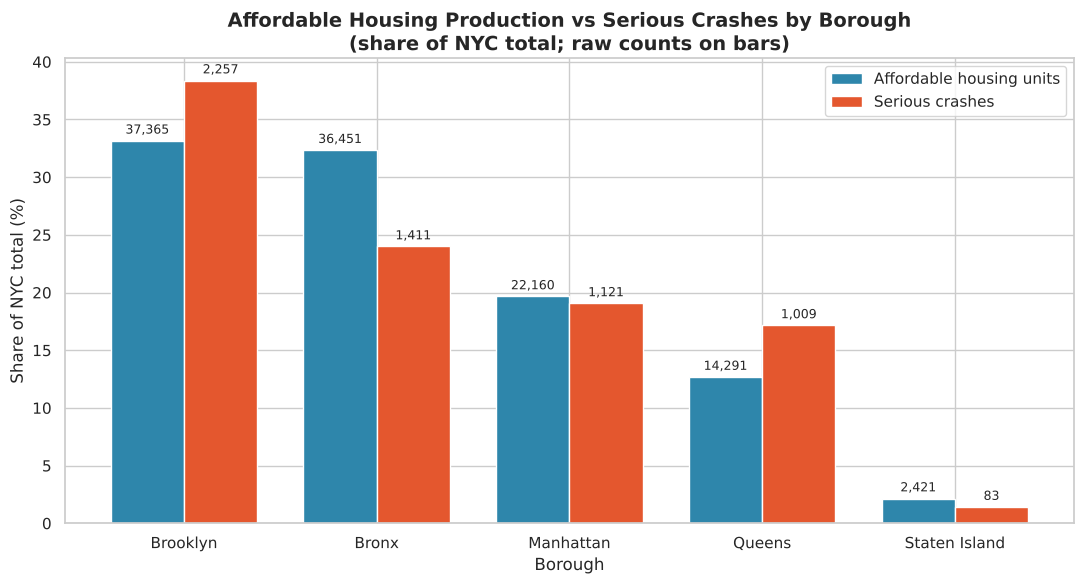

In [6]:
x, w = np.arange(len(boro)), 0.38
fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - w/2, boro["housing_share_%"], w, label="Affordable housing units", color="#2E86AB")
b2 = ax.bar(x + w/2, boro["crash_share_%"],   w, label="Serious crashes",          color="#E4572E")

for bars, raw in [(b1, boro.affordable_units), (b2, boro.serious_crashes)]:
    for bar, val in zip(bars, raw):
        ax.annotate(f"{int(val):,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")

ax.set_xticks(x)
ax.set_xticklabels(boro["borough"])
ax.set_ylabel("Share of NYC total (%)")
ax.set_xlabel("Borough")
ax.set_title("Affordable Housing Production vs Serious Crashes by Borough\n(share of NYC total; raw counts on bars)",
             fontsize=14, weight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("rq2_borough_grouped_bar.png", dpi=150)
plt.show()

In [7]:
top_h = boro.loc[boro.affordable_units.idxmax()]
top_c = boro.loc[boro.serious_crashes.idxmax()]
print(f"Highest affordable housing: {top_h.borough} ({top_h['housing_share_%']:.1f}% of NYC)")
print(f"Highest serious crashes:    {top_c.borough} ({top_c['crash_share_%']:.1f}% of NYC)\n")

gap = boro.assign(gap=boro["crash_share_%"] - boro["housing_share_%"]).sort_values("gap", ascending=False)
print("Crash share minus housing share (positive = more crashes than its housing share):")
print(gap[["borough", "gap"]].round(1).to_string(index=False))

Highest affordable housing: Brooklyn (33.2% of NYC)
Highest serious crashes:    Brooklyn (38.4% of NYC)

Crash share minus housing share (positive = more crashes than its housing share):
      borough  gap
     Brooklyn  5.2
       Queens  4.5
    Manhattan -0.6
Staten Island -0.7
        Bronx -8.4


### RQ2 — Analysis
- **Housing leader:** **Brooklyn** produced the most affordable units (37,365 — 33.2% of NYC), followed very closely by the **Bronx** (36,451 — 32.3%).
- **Crash leader:** **Brooklyn** also had by far the most serious crashes (2,257 — 38.4% of NYC).
- **Same or different?** Brooklyn leads on both. But the other boroughs diverge:
  - **Brooklyn** (+5.2 points) and **Queens** (+4.5 points) have a larger share of crashes than of housing → road safety there is worse than housing growth alone would suggest.
  - The **Bronx** builds almost as much housing as Brooklyn but has a much smaller crash share (24.0% vs 32.3% of housing, −8.4 points).
  - **Manhattan** is balanced (19.7% housing vs 19.1% crashes); **Staten Island** is low on both.
- **Caution:** Raw totals favour large, populous boroughs. A fairer comparison would be per capita or per km of road — this belongs in the limitations section.